In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow

In [22]:
# import data
df = pd.read_csv('../data/raw/day.csv')
df.head(3)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


### 1) Data inspection

In [23]:
# data types
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
None


In [24]:
# missing values
print('\nMissing Values: ', df.isna().sum().sum())


Missing Values:  0


In [25]:
# duplicate rows
print('\nDuplicate rows: ', df.duplicated().sum())


Duplicate rows:  0


Note: The dataset contains no missing values or no duplicate rows.

### 2) Convert 'dteday' to datetime and sort by date

In [26]:
df['dteday'] = pd.to_datetime(df['dteday'], format='%Y-%m-%d')
df = df.sort_values('dteday').reset_index(drop=True)

print(df['dteday'].dtype)
df.head(3)

datetime64[us]


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349


In [27]:
df.tail(3)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796
730,731,2012-12-31,1,1,12,0,1,1,2,0.215833,0.223487,0.577500,0.154846,439,2290,2729


Note: The dataset covers the period from 2011-01-01 to 2012-12-31

###  3) Feature Availability

Feature Dictionary Provided by the Data Source Website

	- instant: record index
	- dteday : date
	- season : season (1:springer, 2:summer, 3:fall, 4:winter)
	- yr : year (0: 2011, 1:2012)
	- mnth : month ( 1 to 12)
	- holiday : weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)
	- weekday : day of the week
	- workingday : if day is neither weekend nor holiday is 1, otherwise is 0.
	+ weathersit : 
		- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
		- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
		- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
		- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
	- temp : Normalized temperature in Celsius. The values are divided to 41 (max)
	- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max)
	- hum: Normalized humidity. The values are divided to 100 (max)
	- windspeed: Normalized wind speed. The values are divided to 67 (max)
	- casual: count of casual users
	- registered: count of registered users
	- cnt: count of total rental bikes including both casual and registered
	

Feature Availability

**Assumption：** Daily weather observations and rental counts bocome available the following morning  
Predictions are made on the evening of day N-1, so observed weather and rental data are available only from day N-2 or earlier.

| Feature | Can target-date value be used as an input? | Treatment |
|---|---|---|
| `instant` | — | Exclude because it is a record ID |
| `dteday` | — | Use the target date for chronological splitting and feature engineering, but not directly as a model input |
| `season` | ○ |  Use the target-date value |
| `yr` | ○ | Use the target-date value |
| `mnth` | ○ | Use the target-date value |
| `holiday` | ○ | Use the target-date value |
| `weekday` | ○ | Use the target-date value |
| `workingday` | ○ | Use the target-date value |
| `weathersit` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `temp` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `atemp` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `hum` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `windspeed` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `casual` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `registered` | × | Use the value from 2 days before the target date（`shift(2)`） |
| `cnt` | ×（target） | Use the target-date value as the target variable. Use the value from 2 days before the target date as an input valriable（`shift(2)`） |

In [28]:
X = ['season', 'yr', 'mnth', 'holiday', 'weekday',
    'workingday', 'weathersit_lag2', 'temp_lag2',
    'atemp_lag2', 'hum_lag2', 'windspeed_lag2', 'casual_lag2',
    'registered_lag2', 'cnt_lag2']
y = 'cnt'
features =  X + [y] + ['dteday']

In [29]:
# caluclate day N-2 features
features_n2 = ['weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

for feature in features_n2:
    df[f'{feature}_lag2'] = df[feature].shift(2)
    
# check the result
df[['dteday', 'cnt', 'cnt_lag2']].head(5)

,dteday,cnt,cnt_lag2
0,2011-01-01,985,NaN
1,2011-01-02,801,NaN
2,2011-01-03,1349,985.0
3,2011-01-04,1562,801.0
4,2011-01-05,1600,1349.0


In [30]:
# check the missing values
print('Missing values before removal: ', df.isna().sum().sum())
# print( df.isna().sum())

# remove rows without day N-2 data (row: 2011-01-01, 2011-01-02)
df_clean = df.dropna().copy() 

# check the missing values
print('Missing values after removal: ', df_clean.isna().sum().sum())

df_clean[['dteday', 'cnt', 'cnt_lag2']].head(5)


Missing values before removal:  16
Missing values after removal:  0


,dteday,cnt,cnt_lag2
2,2011-01-03,1349,985.0
3,2011-01-04,1562,801.0
4,2011-01-05,1600,1349.0
5,2011-01-06,1606,1562.0
6,2011-01-07,1510,1600.0


Text(0.5, 1.0, 'Daily Rental Records from 2011 to 2012')

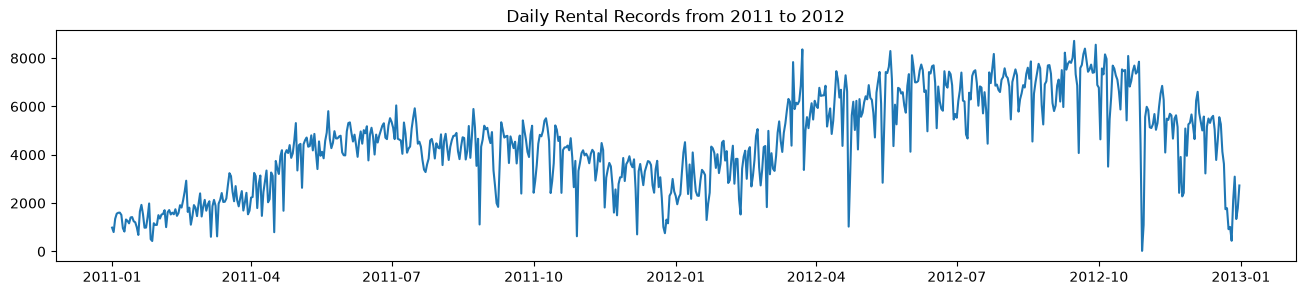

In [31]:
# daily rental records
plt.figure(figsize=(16, 3))
plt.plot(df['dteday'], df['cnt'])
# plt.plot(df['dteday'], df['cnt_lag2'])
plt.title('Daily Rental Records from 2011 to 2012')

Corrlation with Target
cnt                1.000000
cnt_lag2           0.784623
registered_lag2    0.769016
temp_lag2          0.571776
atemp_lag2         0.571765
yr                 0.566710
casual_lag2        0.465604
season             0.406100
mnth               0.279977
weekday            0.067443
workingday         0.061156
hum_lag2           0.037805
holiday           -0.068348
weathersit_lag2   -0.091835
windspeed_lag2    -0.135573
Name: cnt, dtype: float64


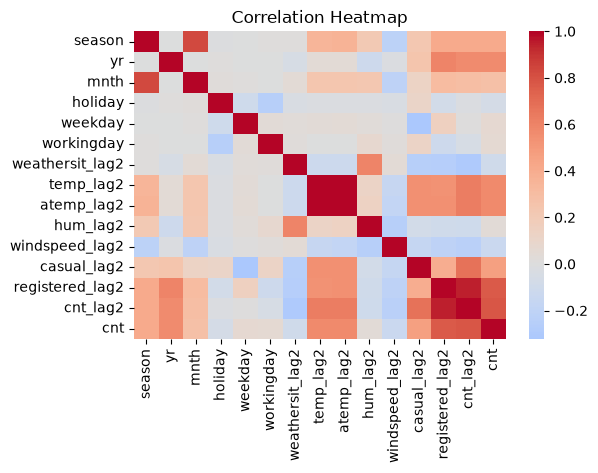

In [32]:
# Correlation among numeric features
plt.figure(figsize=(6,4))
df_num = df[features].select_dtypes(include='number')
corr = df_num.corr()
print('Corrlation with Target')
print(corr['cnt'].sort_values(ascending=False))

sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

### 4) Train Valid Test Sprit 

In [33]:
train = df_clean[features].query('dteday < "2012-05-01"').copy() # 14months
valid = df_clean[features].query('dteday >= "2012-05-01"').query('dteday < "2012-09-01"').copy() #4months
test = df_clean[features].query('dteday >= "2012-09-01"').copy() # 4months

for name, data in [('train', train),('valid', valid),('test', test)]:
    print(
        name,
        'records:', len(data),  
        'period:', data["dteday"].min(),
        '〜', data["dteday"].max()
    )

train records: 484 period: 2011-01-03 00:00:00 〜 2012-04-30 00:00:00
valid records: 123 period: 2012-05-01 00:00:00 〜 2012-08-31 00:00:00
test records: 122 period: 2012-09-01 00:00:00 〜 2012-12-31 00:00:00


In [34]:
train.drop(columns=['dteday'], inplace=True)
valid.drop(columns=['dteday'], inplace=True)
test.drop(columns=['dteday'], inplace=True)


In [35]:
# save the processed data
train.to_csv('../data/processed/train.csv', index=False)
valid.to_csv('../data/processed/valid.csv', index=False)
test.to_csv('../data/processed/test.csv', index=False)

### 5) Baseline Model

Use value for day N-2 as baseline

In [36]:
valid['diff_abs'] = abs(valid['cnt'] - valid['cnt_lag2']) 
MAE_base = valid['diff_abs'].mean()
RMSE_base = np.sqrt((valid['diff_abs'] ** 2).mean())
print(f'Base MAE: {MAE_base}')
print(f'Base RMSE: {RMSE_base}')

Base MAE: 1011.1951219512196
Base RMSE: 1336.4223536431412


- MAE: The baseline model's prediction differ from the actual values by approximately 1,011 rentals on average
- RMSE: Penalizes larger prediction errors more heavily  

### 6) ML Flow

In [ ]:
mlflow.set_tracking_uri(
    "sqlite:///d:/03_Python/bikeshare-mlops/src/mlflow.db"
)
mlflow.set_experiment("Bike_Sharing")

with mlflow.start_run(run_name="Baseline_Lag2"):
    mlflow.log_param("lag_days", 2)
    mlflow.log_metric("MAE", MAE_base)
    mlflow.log_metric("RMSE", RMSE_base)

2026/10/18 01:17:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/18 01:17:11 INFO mlflow.store.db.utils: Updating database tables
2026/10/18 01:17:29 INFO mlflow.tracking.fluent: Experiment with name 'Bike_Sharing' does not exist. Creating a new experiment.
